# AVA: visual clustering and cluster-based aesthetic prediction

This experiment complements, rather than replaces, `model_building_from_ava.ipynb`. We use **k-means**, a course topic, to group visually similar photographs using frozen **CLIP embeddings**, our outside-course technique. Each cluster predicts the mean human AVA rating of its training images.

**Question:** Do visual groups have different aesthetic ratings, and can their training-average ratings predict unseen images better than the global training mean?

Run all cells from the repository root with `data/ava_cleaned_features.parquet` available. The existing feature-extraction notebook creates this file. No image downloads or GPU are required. In your notebook environment, install missing dependencies with `%pip install numpy pandas pyarrow scikit-learn scipy matplotlib joblib`.

We use an **80/20 training/validation split**, not cross-validation yet. Because the 20% split selects `k`, its scores are exploratory validation results, **not an unbiased final test**. Later, compare candidate values using two-fold cross-validation, refitting clusters and cluster score means within each fold; retain a separate final test set if reporting generalization performance.

In [1]:
%matplotlib inline

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import pearsonr, spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import davies_bouldin_score, mean_squared_error, r2_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer, StandardScaler
from threadpoolctl import threadpool_limits

DATA_PATH = Path('data/ava_cleaned_features.parquet')
MODEL_PATH = Path('models/aesthetic_cluster_model.pkl')
RANDOM_STATE = 42
VALIDATION_SIZE = 0.2
K_VALUES = [2, 4, 8, 16, 32]
SILHOUETTE_SAMPLE_SIZE = 2000
STRUCT_NAMES = [
    'brightness', 'contrast', 'center_ratio',
    'r_mean', 'g_mean', 'b_mean', 'r_std', 'g_std', 'b_std',
    'aspect_ratio', 'width', 'height',
]

## 1. Load features and split images

Cluster only the 512-dimensional CLIP vectors so the groups reflect visual content. The 12 structural features are retained for interpreting the groups, not mixed into the clustering distance where pixel dimensions could dominate.

L2 normalization is per image and does not learn from other rows. For unit vectors, squared Euclidean distance between images equals `2 * (1 - cosine similarity)`. We use ordinary Euclidean k-means, **not spherical k-means**: its centroids are not constrained to unit length. Human scores never enter the clustering input.

In [2]:
df = pd.read_parquet(DATA_PATH)
required = {'image_id', 'clip_embedding', 'structural_features', 'mean_score'}
if not required.issubset(df.columns):
    raise ValueError(f'Missing columns: {sorted(required - set(df.columns))}')
if df['image_id'].isna().any() or df['image_id'].astype(str).duplicated().any():
    raise ValueError('Image IDs must be present and unique before splitting.')

X = np.vstack(df['clip_embedding']).astype(np.float32)
X_struct = np.vstack(df['structural_features']).astype(np.float32)
y = df['mean_score'].to_numpy(dtype=np.float64)
if X.shape != (len(df), 512) or X_struct.shape != (len(df), len(STRUCT_NAMES)):
    raise ValueError('Expected 512 CLIP dimensions and 12 structural features per image.')
if not all(np.isfinite(values).all() for values in (X, X_struct, y)):
    raise ValueError('Features and ratings must contain only finite values.')
if np.any(np.linalg.norm(X, axis=1) == 0) or np.any((y < 1) | (y > 10)):
    raise ValueError('Embeddings must be nonzero and AVA mean ratings must be in [1, 10].')

train_idx, val_idx = train_test_split(
    np.arange(len(df)), test_size=VALIDATION_SIZE, random_state=RANDOM_STATE,
)
X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]
if not K_VALUES or any(k < 2 or k >= len(train_idx) for k in K_VALUES):
    raise ValueError('Candidate k values must be at least 2 and smaller than the training size.')
print(f'{len(df):,} images: {len(train_idx):,} training / {len(val_idx):,} validation')
print(f'Training mean: {y_train.mean():.3f}; validation mean: {y_val.mean():.3f}')

20,420 images: 16,336 training / 4,084 validation
Training mean: 5.387; validation mean: 5.381


## 2. Fit clusters and learn their scores

For each candidate `k`, fit k-means on training embeddings only. Estimate each cluster's score using an **unweighted mean of training image ratings** (each photograph counts equally, regardless of its number of votes). Assign validation images to their nearest learned centroid, then look up that cluster's training score.

Select `k` by the lowest **validation RMSE** because prediction is one of our goals. Report **Davies-Bouldin** (lower is better) and sampled **silhouette** (higher is better) on training embeddings as separate geometric diagnostics. Good separation does not necessarily imply good aesthetic prediction. Silhouette uses the same fixed sample for every candidate to keep runtime and memory bounded.

In [3]:
def fit_cluster_model(features, scores, k):
    features = np.asarray(features, dtype=np.float32)
    clusterer = make_pipeline(
        Normalizer(norm='l2'),
        KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE),
    )
    clusterer.fit(features)
    labels = clusterer[-1].labels_
    counts = np.bincount(labels, minlength=k)
    if np.any(counts == 0):
        raise ValueError(f'k={k} produced empty clusters; reduce k or inspect duplicate embeddings.')
    cluster_scores = np.bincount(labels, weights=scores, minlength=k) / counts
    return clusterer, cluster_scores


def prediction_metrics(actual, predicted):
    # Correlations are undefined for the constant global-mean baseline.
    variable = np.ptp(actual) > 0 and np.ptp(predicted) > 0
    return {
        'rmse': float(np.sqrt(mean_squared_error(actual, predicted))),
        'r2': float(r2_score(actual, predicted)),
        'pearson': float(pearsonr(actual, predicted).statistic) if variable else np.nan,
        'spearman': float(spearmanr(actual, predicted).statistic) if variable else np.nan,
    }


def predict_cluster_scores(clusterer, cluster_scores, embeddings):
    embeddings = np.asarray(embeddings, dtype=np.float32)
    expected_dim = clusterer.n_features_in_
    if embeddings.ndim != 2 or embeddings.shape[1] != expected_dim or len(embeddings) == 0:
        raise ValueError(f'Expected a nonempty (N, {expected_dim}) embedding matrix.')
    if not np.isfinite(embeddings).all() or np.any(np.linalg.norm(embeddings, axis=1) == 0):
        raise ValueError('Embeddings must be finite and nonzero.')
    return cluster_scores[clusterer.predict(embeddings)]

In [4]:
baseline_pred = np.full(len(y_val), y_train.mean())
baseline_metrics = prediction_metrics(y_val, baseline_pred)
sample_idx = np.random.default_rng(RANDOM_STATE).choice(
    len(X_train), size=min(SILHOUETTE_SAMPLE_SIZE, len(X_train)), replace=False,
)
results = []
best_model = None
best_rmse = np.inf

# Limit numerical-library threads to avoid saturating a shared laptop.
with threadpool_limits(limits=2):
    for k in K_VALUES:
        clusterer, cluster_scores = fit_cluster_model(X_train, y_train, k)
        labels = clusterer[-1].labels_
        normalized_train = clusterer[0].transform(X_train)
        predicted = predict_cluster_scores(clusterer, cluster_scores, X_val)
        metrics = prediction_metrics(y_val, predicted)
        sample_labels = labels[sample_idx]
        sample_cluster_count = len(np.unique(sample_labels))
        if 1 < sample_cluster_count < len(sample_idx):
            silhouette = silhouette_score(normalized_train[sample_idx], sample_labels)
        else:
            print(f'k={k}: silhouette undefined on the fixed sample; reporting NaN.')
            silhouette = np.nan
        results.append({
            'k': k, **metrics,
            'train_davies_bouldin': davies_bouldin_score(normalized_train, labels),
            'train_silhouette_sample': silhouette,
            'min_train_cluster_size': np.bincount(labels, minlength=k).min(),
        })
        if metrics['rmse'] < best_rmse:
            best_rmse = metrics['rmse']
            best_model = (clusterer, cluster_scores)
        print(f'k={k:2d}: validation RMSE={metrics["rmse"]:.4f}')

results_df = pd.DataFrame(results).sort_values(['rmse', 'k']).reset_index(drop=True)
display(results_df.round(4))
best_clusterer, best_cluster_scores = best_model
best_k = best_clusterer[-1].n_clusters
best_pred = predict_cluster_scores(best_clusterer, best_cluster_scores, X_val)
display(pd.DataFrame([
    {'method': 'Training global mean', **baseline_metrics},
    {'method': f'Cluster means (k={best_k})', **prediction_metrics(y_val, best_pred)},
]).round(4))
print('NaN baseline correlations are undefined, not missing predictions.')
print(f'Selected k={best_k} by validation RMSE; this is not a final test score.')

k= 2: validation RMSE=0.7343


k= 4: validation RMSE=0.7298


k= 8: validation RMSE=0.7266


k=16: validation RMSE=0.7241


k=32: validation RMSE=0.7191


,k,rmse,r2,pearson,spearman,train_davies_bouldin,train_silhouette_sample,min_train_cluster_size
0,32,0.7191,0.0448,0.2126,0.2038,3.6820,0.0289,245
1,16,0.7241,0.0313,0.1787,0.1772,3.9215,0.0289,705
2,8,0.7266,0.0248,0.1587,0.1497,3.9352,0.0273,1433
3,4,0.7298,0.0161,0.1273,0.1210,4.1406,0.0393,3016
4,2,0.7343,0.0039,0.0667,0.0664,4.6162,0.0409,5625


,method,rmse,r2,pearson,spearman
0,Training global mean,0.7358,-0.0001,NaN,NaN
1,Cluster means (k=32),0.7191,0.0448,0.2126,0.2038


NaN baseline correlations are undefined, not missing predictions.
Selected k=32 by validation RMSE; this is not a final test score.


## Final RMSE comparison on the held-out 20%

**Lower RMSE is better**, measured in AVA rating points. Compare the selected model with three guesses: always use the training mean, draw a continuous uniform random score between 1 and 10, or randomly sample an actual training image's mean rating. The last baseline matches the training rating distribution without using the validation labels to generate predictions.

Repeat each random baseline 100 times with a fixed seed and report its mean RMSE and run-to-run standard deviation. This standard deviation describes randomness in guessing, not uncertainty in model performance. Beating random guesses is a low bar; improvement over the training mean is the more informative result. These are validation scores because this same holdout selected `k`, not an independent final test.

,method,validation_rmse,random_run_std
0,Cluster model (k=32),0.7191,0.0000
1,Always guess training mean,0.7358,0.0000
2,Random training rating,1.0338,0.0104
3,"Random uniform score [1, 10]",2.7005,0.0185


Final selected-model validation RMSE: 0.7191 AVA rating points
Against Always guess training mean: better; baseline minus model RMSE = +0.0167
Against Random training rating: better; baseline minus model RMSE = +0.3147
Against Random uniform score [1, 10]: better; baseline minus model RMSE = +1.9814
RMSE reduction versus training-mean guessing: 2.27%


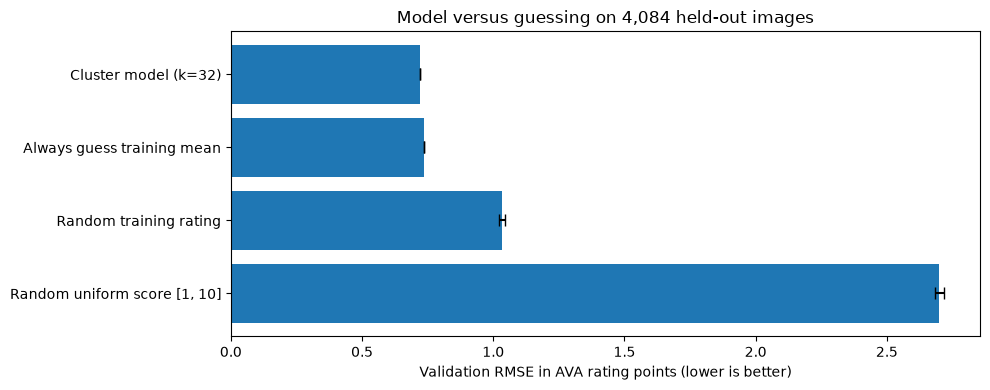

In [5]:
RANDOM_BASELINE_REPEATS = 100
rng = np.random.default_rng(RANDOM_STATE)
uniform_rmse = []
sampled_rating_rmse = []
for _ in range(RANDOM_BASELINE_REPEATS):
    uniform_guess = rng.uniform(1, 10, size=len(y_val))
    sampled_guess = rng.choice(y_train, size=len(y_val), replace=True)
    uniform_rmse.append(np.sqrt(mean_squared_error(y_val, uniform_guess)))
    sampled_rating_rmse.append(np.sqrt(mean_squared_error(y_val, sampled_guess)))

model_rmse = float(np.sqrt(mean_squared_error(y_val, best_pred)))
mean_guess_rmse = baseline_metrics['rmse']
final_rmse_comparison = pd.DataFrame([
    {'method': f'Cluster model (k={best_k})', 'validation_rmse': model_rmse, 'random_run_std': 0.0},
    {'method': 'Always guess training mean', 'validation_rmse': mean_guess_rmse, 'random_run_std': 0.0},
    {'method': 'Random uniform score [1, 10]', 'validation_rmse': np.mean(uniform_rmse),
     'random_run_std': np.std(uniform_rmse, ddof=1)},
    {'method': 'Random training rating', 'validation_rmse': np.mean(sampled_rating_rmse),
     'random_run_std': np.std(sampled_rating_rmse, ddof=1)},
]).sort_values('validation_rmse').reset_index(drop=True)
display(final_rmse_comparison.round(4))
print(f'Final selected-model validation RMSE: {model_rmse:.4f} AVA rating points')
for row in final_rmse_comparison.to_dict(orient='records'):
    if row['method'].startswith('Cluster model'):
        continue
    difference = row['validation_rmse'] - model_rmse
    outcome = 'better' if difference > 0 else 'worse' if difference < 0 else 'equal'
    print(f'Against {row["method"]}: {outcome}; baseline minus model RMSE = {difference:+.4f}')
if mean_guess_rmse > 0:
    improvement = 100 * (mean_guess_rmse - model_rmse) / mean_guess_rmse
    print(f'RMSE reduction versus training-mean guessing: {improvement:.2f}%')

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(final_rmse_comparison['method'], final_rmse_comparison['validation_rmse'],
        xerr=final_rmse_comparison['random_run_std'], capsize=4)
ax.invert_yaxis()
ax.set_xlabel('Validation RMSE in AVA rating points (lower is better)')
ax.set_title(f'Model versus guessing on {len(y_val):,} held-out images')
fig.tight_layout()
plt.show()

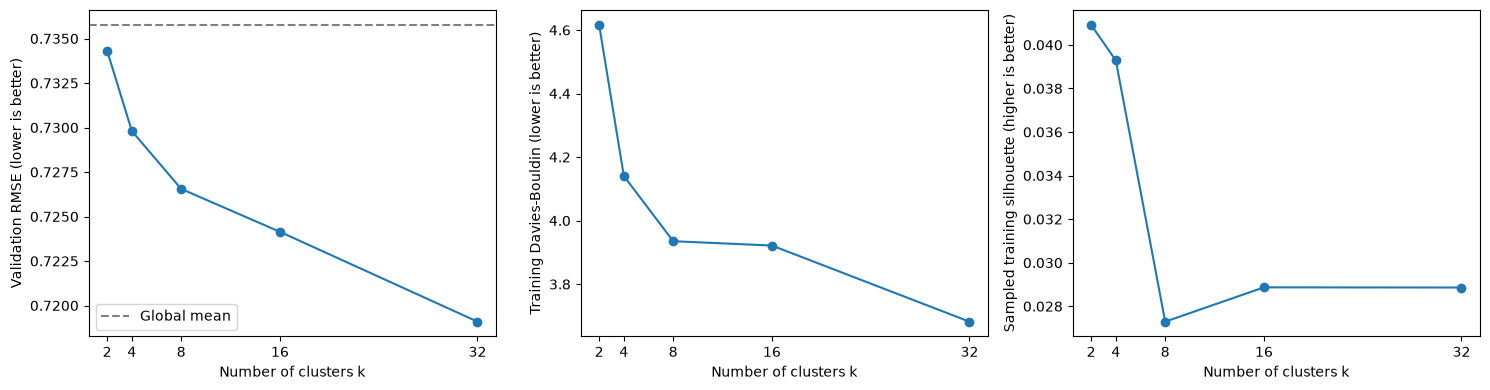

In [6]:
ordered = results_df.sort_values('k')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(ordered['k'], ordered['rmse'], marker='o')
axes[0].axhline(baseline_metrics['rmse'], color='grey', linestyle='--', label='Global mean')
axes[0].set_ylabel('Validation RMSE (lower is better)')
axes[0].legend()
axes[1].plot(ordered['k'], ordered['train_davies_bouldin'], marker='o')
axes[1].set_ylabel('Training Davies-Bouldin (lower is better)')
axes[2].plot(ordered['k'], ordered['train_silhouette_sample'], marker='o')
axes[2].set_ylabel('Sampled training silhouette (higher is better)')
for ax in axes:
    ax.set_xlabel('Number of clusters k')
    ax.set_xticks(K_VALUES)
fig.tight_layout()
plt.show()

## 3. Explore the selected visual groups

Compare training cluster means with the human validation means, validation error and cluster sizes. Small clusters have less reliable score estimates. Structural-feature averages describe visual differences, but do not establish causal effects on aesthetics. Width and height reflect stored image resolution, not necessarily photographic quality.

The PCA scatter is a **2D visualization only**; clustering still uses all 512 CLIP dimensions. PCA and the structural-feature standardizer are fit on training data only. The representative table gives training image IDs nearest each centroid; the parquet contains no raw photos, so use those IDs in the existing notebook's image-display workflow to inspect and name the groups. Do not infer semantic labels from cluster numbers alone.

,train_count,train_score_mean,train_score_std,validation_count,validation_score_mean,validation_rmse
cluster,,,,,,
0,407,5.807,0.639,122,5.712,0.731
11,339,5.743,0.695,98,5.629,0.805
24,672,5.712,0.691,156,5.711,0.685
9,311,5.606,0.739,88,5.678,0.744
25,582,5.575,0.709,137,5.667,0.766
21,424,5.550,0.691,108,5.521,0.714
15,442,5.549,0.692,97,5.592,0.690
13,610,5.515,0.796,147,5.385,0.864
12,567,5.479,0.695,162,5.368,0.596


NaN validation statistics indicate a cluster with no validation images.


,brightness,contrast,center_ratio,r_mean,g_mean,b_mean,r_std,g_std,b_std,aspect_ratio,width,height
cluster,,,,,,,,,,,,
0,0.417,0.218,0.879,0.413,0.418,0.423,0.227,0.219,0.250,1.368,641.802979,496.829987
1,0.451,0.233,0.959,0.487,0.442,0.404,0.249,0.238,0.233,1.290,608.455017,501.160004
2,0.410,0.216,0.963,0.470,0.393,0.341,0.236,0.222,0.210,1.116,570.929993,540.887024
3,0.414,0.224,0.919,0.430,0.412,0.378,0.228,0.227,0.241,1.247,603.854004,510.131989
4,0.442,0.221,0.948,0.445,0.440,0.439,0.232,0.224,0.236,1.260,602.169983,504.019989
5,0.403,0.197,0.965,0.425,0.408,0.315,0.212,0.202,0.194,1.167,586.583984,528.658997
6,0.454,0.215,1.000,0.453,0.458,0.435,0.229,0.219,0.227,1.251,606.109985,513.375977
7,0.406,0.234,0.953,0.431,0.400,0.366,0.244,0.236,0.237,1.164,595.228027,540.473022
8,0.366,0.214,1.012,0.418,0.353,0.299,0.241,0.219,0.212,1.169,579.155029,525.864014


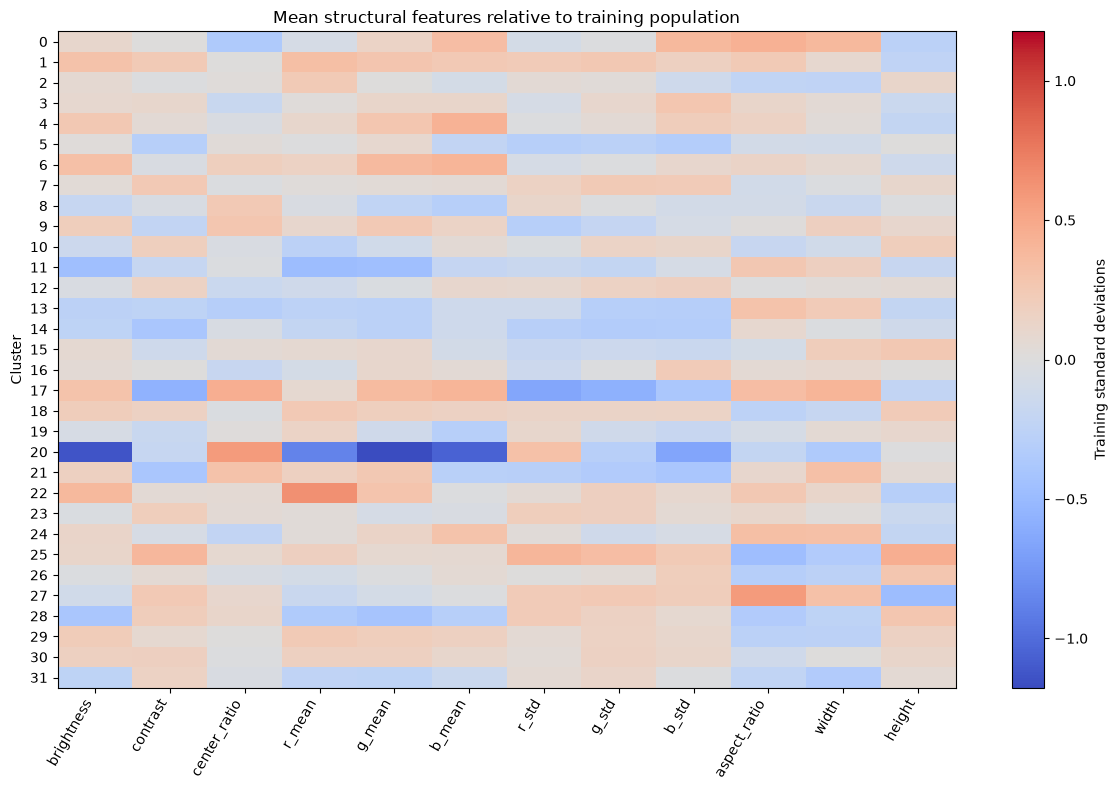

In [7]:
train_labels = best_clusterer.predict(X_train)
val_labels = best_clusterer.predict(X_val)
train_summary = pd.DataFrame({'cluster': train_labels, 'human_score': y_train}).groupby('cluster').agg(
    train_count=('human_score', 'size'),
    train_score_mean=('human_score', 'mean'),
    train_score_std=('human_score', 'std'),
)
val_summary = pd.DataFrame({
    'cluster': val_labels, 'human_score': y_val, 'squared_error': (y_val - best_pred) ** 2,
}).groupby('cluster').agg(
    validation_count=('human_score', 'size'),
    validation_score_mean=('human_score', 'mean'),
    validation_mse=('squared_error', 'mean'),
)
val_summary['validation_rmse'] = np.sqrt(val_summary.pop('validation_mse'))
cluster_summary = train_summary.join(val_summary).sort_values('train_score_mean', ascending=False)
display(cluster_summary.round(3))
print('NaN validation statistics indicate a cluster with no validation images.')

structural_df = pd.DataFrame(X_struct[train_idx], columns=STRUCT_NAMES)
structural_df['cluster'] = train_labels
display(structural_df.groupby('cluster').mean().round(3))

struct_scaler = StandardScaler().fit(X_struct[train_idx])
standardized = pd.DataFrame(struct_scaler.transform(X_struct[train_idx]), columns=STRUCT_NAMES)
standardized['cluster'] = train_labels
feature_profile = standardized.groupby('cluster').mean()
fig, ax = plt.subplots(figsize=(12, max(4, best_k * 0.25)))
limit = max(float(np.abs(feature_profile.to_numpy()).max()), 0.01)
heatmap = ax.imshow(feature_profile, aspect='auto', cmap='coolwarm', vmin=-limit, vmax=limit)
ax.set_xticks(range(len(STRUCT_NAMES)), STRUCT_NAMES, rotation=60, ha='right')
ax.set_yticks(range(best_k), feature_profile.index)
ax.set_ylabel('Cluster')
ax.set_title('Mean structural features relative to training population')
fig.colorbar(heatmap, ax=ax, label='Training standard deviations')
fig.tight_layout()
plt.show()

In [2]:
with threadpool_limits(limits=2):
    pca = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE)
    pca.fit(best_clusterer[0].transform(X_train))
    val_2d = pca.transform(best_clusterer[0].transform(X_val))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(val_2d[:, 0], val_2d[:, 1], c=val_labels, cmap='tab20', s=8, alpha=0.5)
axes[0].set_title(f'Validation images by visual cluster (k={best_k})')
scores_plot = axes[1].scatter(
    val_2d[:, 0], val_2d[:, 1], c=y_val, cmap='viridis', s=8, alpha=0.5,
)
axes[1].set_title('Same validation images by human AVA score')
fig.colorbar(scores_plot, ax=axes[1], label='Human mean rating')
for ax in axes:
    ax.set_xlabel('Principal component 1')
    ax.set_ylabel('Principal component 2')
fig.tight_layout()
plt.show()
print(f'2D PCA captures {pca.explained_variance_ratio_.sum():.1%} of training embedding variance.')
print('Cluster colors repeat beyond 20 groups; this projection is not a separation metric.')

normalized_train = best_clusterer[0].transform(X_train)
representatives = []
for cluster in range(best_k):
    members = np.flatnonzero(train_labels == cluster)
    distances = np.linalg.norm(
        normalized_train[members] - best_clusterer[-1].cluster_centers_[cluster], axis=1,
    )
    for rank, position in enumerate(np.argsort(distances)[:3], start=1):
        local_idx = members[position]
        representatives.append({
            'cluster': cluster, 'rank': rank,
            'image_id': str(df.iloc[train_idx[local_idx]]['image_id']),
            'human_score': y_train[local_idx],
            'cluster_prediction': best_cluster_scores[cluster],
            'centroid_distance': distances[position],
        })
representatives_df = pd.DataFrame(representatives)
display(representatives_df.round(3))

NameError: name 'threadpool_limits' is not defined

## 4. Save the separate clustering model

Save the selected **training-only** model to `models/aesthetic_cluster_model.pkl`, leaving the Ridge artifact untouched. The saved pipeline normalizes embeddings automatically. For Unsplash, extract CLIP vectors with the same `openai/clip-vit-base-patch32` backbone and image preprocessing as AVA, then call `predict_cluster_scores(artifact['clusterer'], artifact['cluster_scores'], unsplash_embeddings)`.

These predictions estimate AVA-style ratings, not validated Unsplash human preferences. They are constant within each cluster and may miss differences in execution between similar subjects. The model is not refit on validation data here, so the saved predictions match this experiment. Only load joblib files you trust.

In [9]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
artifact = {
    'clusterer': best_clusterer,
    'cluster_scores': best_cluster_scores,
    'clip_model_id': 'openai/clip-vit-base-patch32',
    'feature_column': 'clip_embedding',
    'k': best_k,
    'random_state': RANDOM_STATE,
    'validation_size': VALIDATION_SIZE,
    'selection_metric': 'validation_rmse',
    'training_image_ids': df.iloc[train_idx]['image_id'].astype(str).tolist(),
    'validation_image_ids': df.iloc[val_idx]['image_id'].astype(str).tolist(),
    'candidate_results': results_df.to_dict(orient='records'),
}
joblib.dump(artifact, MODEL_PATH)
loaded = joblib.load(MODEL_PATH)
reloaded_pred = predict_cluster_scores(loaded['clusterer'], loaded['cluster_scores'], X_val)
np.testing.assert_allclose(reloaded_pred, best_pred)
assert set(train_idx).isdisjoint(val_idx)
assert len(train_idx) + len(val_idx) == len(df)
assert np.isfinite(reloaded_pred).all()
assert np.all((reloaded_pred >= 1) & (reloaded_pred <= 10))
print(f'Saved and verified {MODEL_PATH}; Ridge model unchanged.')

Saved and verified models/aesthetic_cluster_model.pkl; Ridge model unchanged.
